# · Data overview

Before building anything, I want to know what this dataset actually contains
and what it can't tell me.

**Key takeaways**
1. Each row is one flight option as seen on Expedia on one day. The same
   flights were checked again and again, so I can follow a price over time.
2. 82M rows, 16 major US airports, one-way domestic flights, searched
   between April and October 2022.
3. Prices only go out to **60 days before departure**, so I can't say
   anything about booking months in advance.
4. Fares are skewed (median $305) and cluster at set price levels. That's
   why I measure savings in percent as well as dollars.
5. Some collection days are missing or partial. A missing price is not a
   price change, and I have to treat it that way.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

from flight_pricing.data import connect
from flight_pricing.plotting import SERIES, use_style

use_style()
con = connect()

def q(sql):
    return con.sql(sql).df()

## What one row means

The data is the Kaggle [Flight Prices](https://www.kaggle.com/datasets/dilwong/flightprices)
dataset, scraped from Expedia in 2022.

In [2]:
q("SELECT * FROM itin LIMIT 1").T.head(15)

,0
legId,a0a686c3ef6514cf16b2912229857068
searchDate,2022-04-16 00:00:00
flightDate,2022-04-19 00:00:00
startingAirport,IAD
destinationAirport,LGA
fareBasisCode,QAA0JFEN
travelDuration,PT3H42M
elapsedDays,0
isBasicEconomy,False
isRefundable,False


Reading this row: on **April 16, 2022**, Expedia offered a trip on
**April 19** from **IAD → LGA** (Washington Dulles to New York LaGuardia),
connecting in Raleigh on United and then Delta, for **$448.60** including
taxes, with 9 seats left at that price.

The columns I'll actually use:

| Column | Meaning |
|---|---|
| `searchDate`, `flightDate` | When the price was seen, and when the flight leaves. The gap between them is days before departure. |
| `startingAirport`, `destinationAirport` | The route |
| `legId` | ID for one specific itinerary, used to follow it over time |
| `totalFare` | What I'd pay, taxes included |
| `isNonStop`, `isBasicEconomy` | Ticket type |
| `seatsRemaining` | Seats left at this price |

The rest are per-leg details (airline, times, aircraft) that I'll pull in
when needed.

## Coverage

In [2]:
q("""
SELECT count(*) AS rows,
       count(DISTINCT startingAirport) AS airports,
       count(DISTINCT startingAirport || destinationAirport) AS routes,
       min(searchDate) AS first_search, max(searchDate) AS last_search,
       max(flightDate) AS last_flight
FROM itin
""")

,rows,airports,routes,first_search,last_search,last_flight
0,82138753,16,235,2022-04-16,2022-10-05,2022-11-19


16 major airports (ATL, BOS, CLT, DEN, DFW, DTW, EWR, IAD, JFK, LAX, LGA,
MIA, OAK, ORD, PHL, SFO) and 235 of the 240 possible routes between them.
So this is busy domestic hub-to-hub travel, one way only. I mostly fly
internationally, so this is a real limitation: the method should carry
over, but the numbers might not.

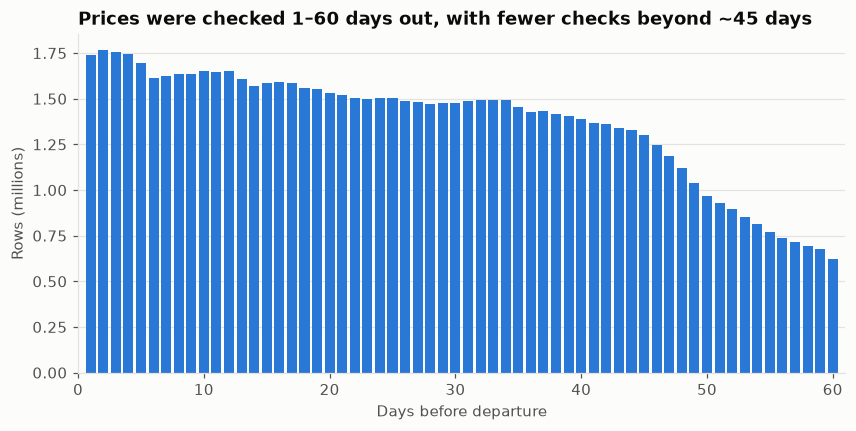

In [3]:
days_ahead = q("""
SELECT datediff('day', searchDate, flightDate) AS days_ahead, count(*) AS n
FROM itin GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots()
ax.bar(days_ahead.days_ahead, days_ahead.n / 1e6, width=0.8, color=SERIES[0])
ax.set_title("Prices were checked 1–60 days out, with fewer checks beyond ~45 days")
ax.set_xlabel("Days before departure")
ax.set_ylabel("Rows (millions)")
ax.set_xlim(0, 61)
plt.show()

Nothing goes past **60 days**, which is the biggest limitation of the
dataset. I can't test whether booking months ahead pays off. Coverage also
thins out after about 45 days, so anything I estimate that far out rests on
less data.

## Fares

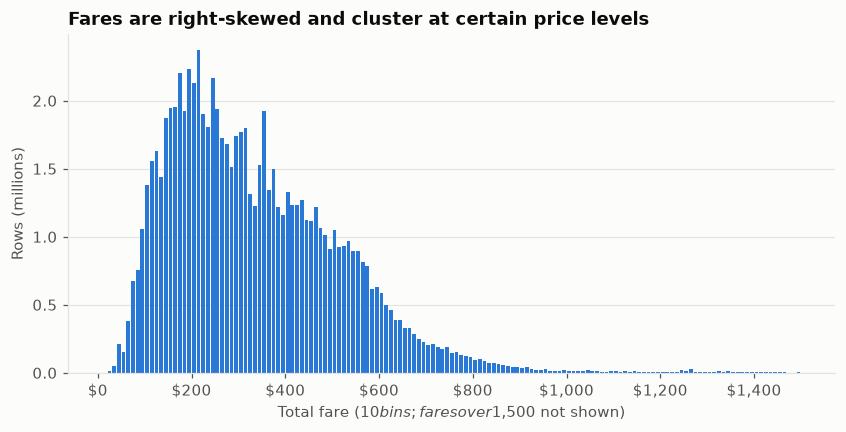

,median,mean,p25,p75,share_nonstop,share_basic_econ
0,305.2,340.39,197.1,452.09,0.27,0.14


In [4]:
fare_hist = q("""
SELECT floor(totalFare / 10) * 10 AS fare_bin, count(*) AS n
FROM itin WHERE totalFare < 1500 GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots()
ax.bar(fare_hist.fare_bin + 5, fare_hist.n / 1e6, width=8, color=SERIES[0])
ax.set_title("Fares are right-skewed and cluster at certain price levels")
ax.set_xlabel("Total fare ($10 bins; fares over $1,500 not shown)")
ax.set_ylabel("Rows (millions)")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
plt.show()

q("""
SELECT median(totalFare) AS median, avg(totalFare) AS mean,
       quantile_cont(totalFare, 0.25) AS p25, quantile_cont(totalFare, 0.75) AS p75,
       avg(isNonStop::INT) AS share_nonstop, avg(isBasicEconomy::INT) AS share_basic_econ
FROM itin
""").round(2)

The median fare is $305, and the mean is higher ($340) because a few
expensive tickets pull it up. Since $30 off a $130 ticket means much more
than $30 off a $900 one, I'll report savings in percent and dollars.

The spikes surprised me. My guess is that airlines sell seats in fixed fare
classes, so prices land on the same few levels and **jump** between them
rather than drifting smoothly. I'll check this out in a future notebook. If it's true,
a model where prices move between levels fits well, such as a Markov chain.

27% of options are nonstop and 14% are basic economy.

## Data quality

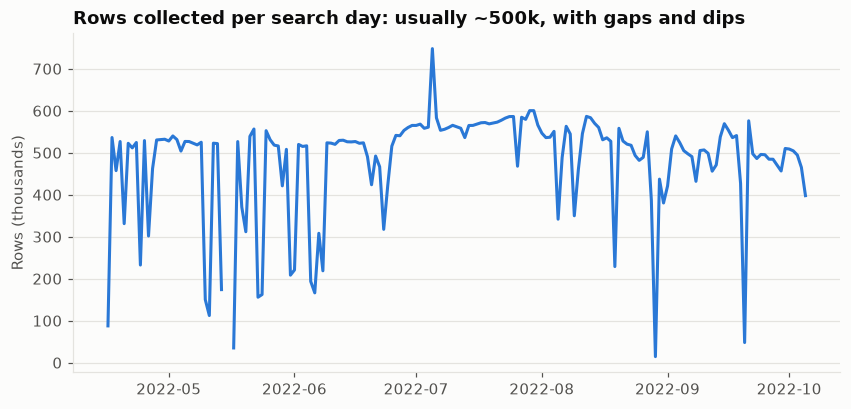

In [5]:
per_day = q("SELECT searchDate, count(*) AS n FROM itin GROUP BY 1 ORDER BY 1")
all_days = pd.date_range(per_day.searchDate.min(), per_day.searchDate.max())
per_day_full = per_day.set_index(pd.to_datetime(per_day.searchDate)).n.reindex(all_days)

fig, ax = plt.subplots()
ax.plot(per_day_full.index, per_day_full / 1e3, color=SERIES[0])
ax.set_title("Rows collected per search day: usually ~500k, with gaps and dips")
ax.set_ylabel("Rows (thousands)")
plt.show()

The scraper usually collected about 500k rows a day, but May 15–16 are
missing entirely and 19 of 171 days are only partly collected. If a flight
has no price on one of those days, that's a collection gap, not a sign it
sold out. My backtest can't treat it as a price change.

`totalTravelDistance` is missing for 7% of rows. Every other column I use is
complete.

## Next:

- How consistently is each itinerary tracked, and do itineraries disappear
  before departure?
- How does the cheapest fare for a route and date move as departure gets
  closer?
- Do prices really jump between fixed levels?